In [2]:
import numpy as np
import matplotlib.pyplot as plt

#### Let's define the parameters here:
dt is the time step so when the total duration is 100ms, it means that we are chopping 0.1 second into 1000 pieces. 

In [3]:
dt = 0.1             # ms
duration = 100.0     # ms
time = np.arange(0, duration, dt)
num_steps = len(time)
tau = 10.0           # membrane time constant (ms)
resistance = 1.0     # membrane resistance (mOhm)
threshold = 1.0      # spike threshold (mV)
reset = 0.0          # reset potential (mV)
Input_current = 1.3  # nv

#### Now we simulate a single Leaky Integrate-and-Fire neuron using Euler integration.

In [4]:
def simulate_lif(input_current, dt=dt, tau=tau, resistance=resistance, 
                 threshold=threshold, reset=reset):
    voltage = np.zeros(len(input_current))
    voltage[0] = reset
    spikes = np.zeros(len(input_current))

    for t in range(len(input_current) - 1):
        # Leak and Integrate (Euler update)
        leak = -(voltage[t] - reset)
        integrate = resistance * input_current[t]
        voltage[t + 1] = voltage[t] + (dt / tau) * (leak + integrate)

        # Fire and Reset
        if voltage[t + 1] >= threshold:
            voltage[t + 1] = reset
            spikes[t + 1] = 1.0

    return voltage, spikes

#### Using Matplotlib to plot

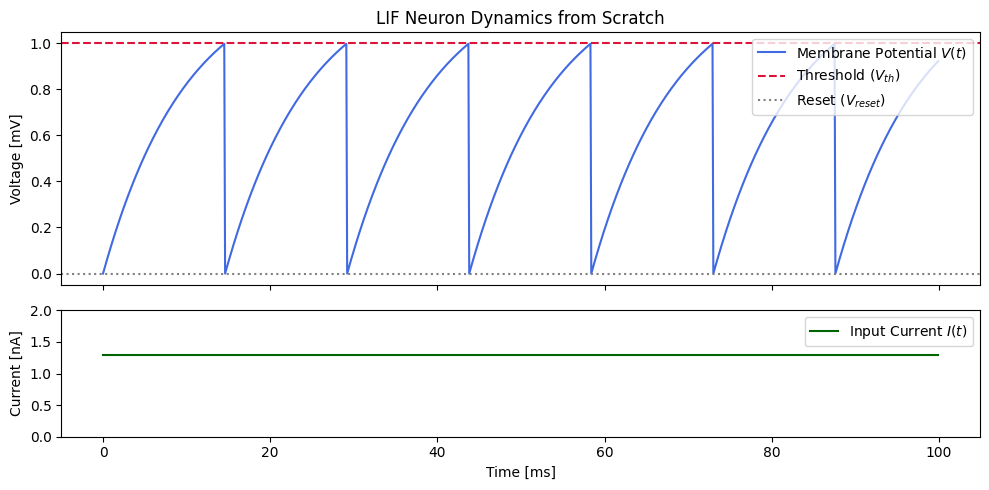

In [5]:
# Constant input current of 1.2 nA
I_const = np.full(num_steps, 1.3)
voltage, spikes = simulate_lif(I_const)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

# Plot Voltage
ax1.plot(time, voltage, label="Membrane Potential $V(t)$", color="royalblue")
ax1.axhline(threshold, color="crimson", linestyle="--", label="Threshold ($V_{th}$)")
ax1.axhline(reset, color="gray", linestyle=":", label="Reset ($V_{reset}$)")
ax1.set_ylabel("Voltage [mV]")
ax1.set_title("LIF Neuron Dynamics from Scratch")
ax1.legend(loc="upper right")

# Plot Input Current
ax2.plot(time, I_const, color="darkgreen", label="Input Current $I(t)$")
ax2.set_xlabel("Time [ms]")
ax2.set_ylabel("Current [nA]")
ax2.set_ylim(0, 2.0)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

#### That was Easy right?
#### now switch the DC input current with spike inputs. this makes the neuron a little more unpredictable
#### at first spikes are sparse but they are more dense between 50ms to 80ms. run the cell to see the results

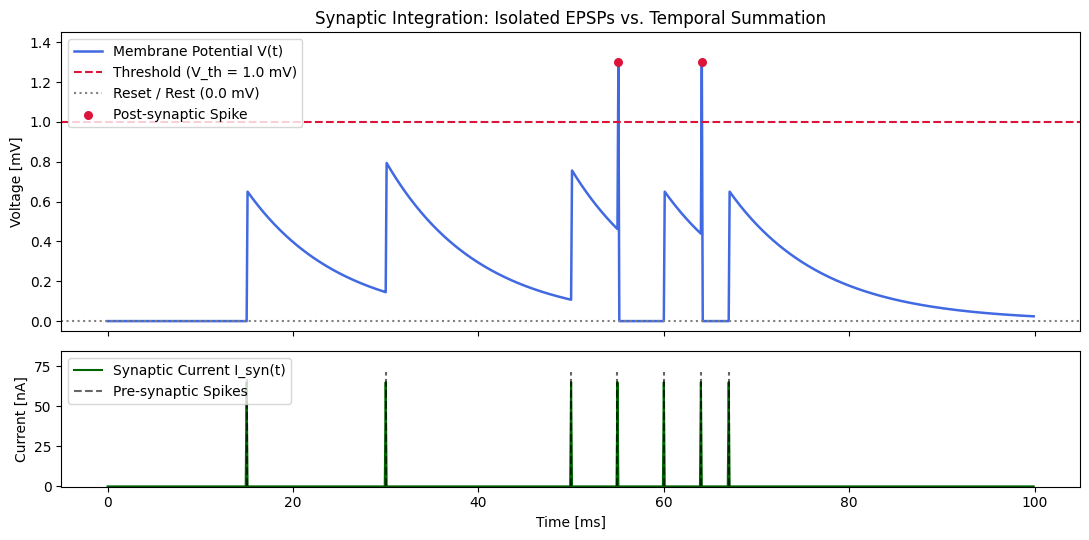

In [7]:
pre_spike_times = [15.0, 30.0, 50.0, 55.0, 60.0, 64.0, 67.0]

I_syn = np.zeros(num_steps)
synaptic_weight = 65.0  # Current pulse strength (nA)
pulse_duration_steps = 1.0 # Duration pulse

for st in pre_spike_times:
    idx = int(st / dt) # indexing spikes
    if idx < num_steps:
        I_syn[idx : min(idx + pulse_duration_steps, num_steps)] = synaptic_weight

# Simulate post-synaptic neuron response using simulate_lif() we defined erlier
v_syn, s_syn = simulate_lif(I_syn)

# Connect spike peaks visually to remove gaps in voltage trace
v_plot = v_syn.copy()
post_spike_indices = np.where(s_syn == 1.0)[0]
v_plot[post_spike_indices] = 1.3

# Visualization
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})

# Top Plot: Membrane Potential
ax1.plot(time, v_plot, label="Membrane Potential V(t)", color="royalblue", linewidth=1.8)
ax1.axhline(threshold, color="crimson", linestyle="--", label="Threshold (V_th = 1.0 mV)")
ax1.axhline(reset, color="gray", linestyle=":", label="Reset / Rest (0.0 mV)")

# Mark post-synaptic output spikes
if len(post_spike_indices) > 0:
    ax1.scatter(time[post_spike_indices], np.full(len(post_spike_indices), 1.3), 
                color="crimson", s=30, zorder=5, label="Post-synaptic Spike")

ax1.set_ylabel("Voltage [mV]")
ax1.set_ylim(-0.05, 1.45)
ax1.set_title("Synaptic Integration: Isolated EPSPs vs. Temporal Summation")
ax1.legend(loc="upper left")

# Bottom Plot: Pre-synaptic Input Spikes & Injected Current
ax2.plot(time, I_syn, color="darkgreen", label="Synaptic Current I_syn(t)")
ax2.vlines(pre_spike_times, ymin=0, ymax=synaptic_weight * 1.1, color="black", linestyle="--", alpha=0.6, label="Pre-synaptic Spikes")
ax2.set_xlabel("Time [ms]")
ax2.set_ylabel("Current [nA]")
ax2.set_ylim(-0.2, synaptic_weight * 1.3)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

#### we can absolutely do anything ourselfs using only python and maybe with a little bit of a help of numpy
#### but we can also use libraries like SNNtorch and write a cleaner code with much less time to do what we wanted to do

In [ ]:

# you can install snntorch using pip: !pip install snntorch
import torch
import snntorch as snn

torch.manual_seed(42)


#### Generate an input spike train across time steps with probability of 8%
#### we defined two neurons with different betas. beta is the Decay Factor of membrane. (e.g. beta= 0.95 meaning 0.05 leak)

$$\beta = \exp\left(-\frac{\Delta t}{\tau}\right) \approx 1 - \frac{\Delta t}{\tau}$$
Also Defined two LIF neurons:
1. beta = 0.95 -> Slow leak (High memory of past inputs)
2. beta = 0.70 -> Fast leak (Low memory and needs more packed spikes to fire)

In [42]:
spk_in = torch.bernoulli(torch.full((num_steps, 1), 0.08))

lif_slow_leak = snn.Leaky(beta=0.95, threshold=1.0, reset_mechanism="zero")
lif_fast_leak = snn.Leaky(beta=0.70, threshold=1.0, reset_mechanism="zero")

# State holders
mem_slow = torch.zeros(1)
mem_fast = torch.zeros(1)

mem_rec_slow = []
spk_rec_slow = []
mem_rec_fast = []
spk_rec_fast = []

In [15]:
# Simulation loop
synaptic_weight = 0.45
for step in range(num_steps):
    current_input = spk_in[step] * weight

    # Update slow leak neuron
    spk_s, mem_slow = lif_slow_leak(current_input, mem_slow)
    mem_rec_slow.append(mem_slow.item())
    spk_rec_slow.append(spk_s.item())

    # Update fast leak neuron
    spk_f, mem_fast = lif_fast_leak(current_input, mem_fast)
    mem_rec_fast.append(mem_fast.item())
    spk_rec_fast.append(spk_f.item())

#### The rest is just visualizations. we inject the same input into two different behave neurons then plot their outputs.

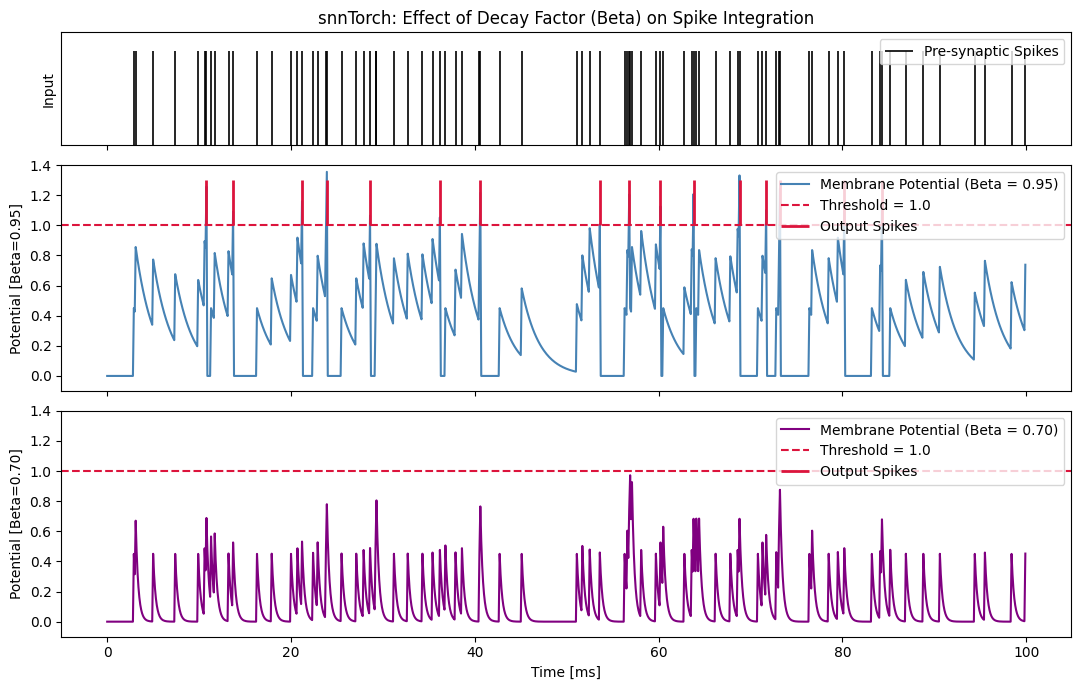

In [16]:

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2, 2]})

# First Subplot: Input Spikes
spike_in_times = time[spk_in.squeeze().numpy() == 1.0]
ax1.vlines(spike_in_times, ymin=0, ymax=1, color="black", linewidth=1.2, label="Pre-synaptic Spikes")
ax1.set_ylabel("Input")
ax1.set_ylim(0, 1.2)
ax1.set_yticks([])
ax1.set_title("snnTorch: Effect of Decay Factor (Beta) on Spike Integration")
ax1.legend(loc="upper right")

# Second Subplot: Slow Leak (Beta = 0.95)
ax2.plot(time, mem_rec_slow, color="steelblue", linewidth=1.5, label="Membrane Potential (Beta = 0.95)")
ax2.axhline(1.0, color="crimson", linestyle="--", label="Threshold = 1.0")
out_spikes_slow = time[np.array(spk_rec_slow) == 1.0]
ax2.vlines(out_spikes_slow, ymin=1.0, ymax=1.3, color="crimson", linewidth=2.0, label="Output Spikes")
ax2.set_ylabel("Potential [Beta=0.95]")
ax2.set_ylim(-0.1, 1.4)
ax2.legend(loc="upper right")

# Third Subplot: Fast Leak (Beta = 0.70)
ax3.plot(time, mem_rec_fast, color="purple", linewidth=1.5, label="Membrane Potential (Beta = 0.70)")
ax3.axhline(1.0, color="crimson", linestyle="--", label="Threshold = 1.0")
out_spikes_fast = time[np.array(spk_rec_fast) == 1.0]
ax3.vlines(out_spikes_fast, ymin=1.0, ymax=1.3, color="crimson", linewidth=2.0, label="Output Spikes")
ax3.set_xlabel("Time [ms]")
ax3.set_ylabel("Potential [Beta=0.70]")
ax3.set_ylim(-0.1, 1.4)
ax3.legend(loc="upper right")

plt.tight_layout()
plt.show()